# Analisis Kualitas dan Karakteristik Data Properti Residensial
### Studi Kasus Data Cleansing & Exploratory Data Analysis (EDA) dengan Python

**Sumber data:** `property_without_duplicates.csv` (dataset yang dipakai pada notebook *How to Handle Inconsistent Data in Python*, Hamizan Hibatullah)
**Tools:** Python, pandas, matplotlib, seaborn

**Nama** : Shafwan Mumtaz
**Kelas** : 04TPLE005
**NIM** : 2241011450529 

## 1. Latar Belakang

Data properti biasanya dikumpulkan dari banyak sumber dan diinput oleh banyak orang. Akibatnya, data sering mengandung masalah kualitas: baris ganda, nilai kosong, tipe data yang salah, dan penulisan yang tidak konsisten (misalnya nama jalan `berkeley`, `Berkeley`, dan `BERKELEY` yang sebenarnya sama).

Jika masalah ini tidak ditangani, hasil analisis bisa menyesatkan. Contohnya, satu jalan yang sama akan terhitung sebagai tiga jalan berbeda saat dihitung per wilayah.

Karena itu, sebelum menganalisis, seorang data analyst perlu memastikan data **bersih dan konsisten**, baru kemudian menggali pola di dalamnya.

## 2. Objektif Analisis

1. Melakukan *pre-processing* data: import library, loading data, menangani duplikat, menangani *missing value*, dan memeriksa tipe data.
2. Mengidentifikasi dan menyeragamkan nilai yang tidak konsisten pada kolom `ST_NAME`.
3. Melakukan *Exploratory Data Analysis* (EDA) untuk memahami karakteristik properti: jumlah kamar tidur, kamar mandi, luas bangunan, status hunian, dan sebaran per jalan.
4. Menarik kesimpulan dan memberi saran berdasarkan temuan.

## 3. Kamus Data

| Kolom | Arti |
|---|---|
| `PID` | ID properti (di file asli kolom ini bernama `lai`, kemungkinan salah nama dan akan kita rename) |
| `ST_NUM` | Nomor rumah/jalan |
| `ST_NAME` | Nama jalan |
| `OWN_OCCUPIED` | Apakah dihuni pemilik (`Y` = ya, `N` = tidak) |
| `NUM_BEDROOMS` | Jumlah kamar tidur |
| `NUM_BATH` | Jumlah kamar mandi |
| `SQ_FT` | Luas bangunan (square feet) |

## 4. Pre-Processing Data

### 4.1 Import Library

Kita memanggil library yang dibutuhkan:
- `pandas` untuk mengolah data tabel,
- `matplotlib` dan `seaborn` untuk visualisasi.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

### 4.2 Loading Data

Data dibaca dengan `pd.read_csv()`. Kode di bawah mencoba membaca dari link GitHub dulu; kalau tidak ada internet, ia membaca file lokal dengan nama yang sama.

In [2]:
url = "https://raw.githubusercontent.com/ham407/Data-Cleansing-Using-Python/main/Datasets/property_without_duplicates.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("property_without_duplicates.csv")

df

,lai,ST_NUM,ST_NAME,OWN_OCCUPIED,NUM_BEDROOMS,NUM_BATH,SQ_FT
0,100001000,104,PUTNAM,Y,3.0,1.0,900.0
1,100002000,197,LXT,N,1.0,1.0,900.0
2,100003000,199,LEXINGTON,N,1.0,1.0,850.0
3,100004000,201,berkeley,Y,1.0,1.0,700.0
4,100005000,203,BERKELEY,Y,3.0,2.0,975.0
5,100006000,207,Berkeley,Y,1.0,1.0,800.0
6,100007000,209,WASHINGTON,Y,2.0,1.0,950.0
7,100008000,213,TREMONT,Y,1.0,1.0,900.0
8,100009000,215,TREMONT,Y,1.0,2.0,900.0


Kolom pertama bernama `lai`, padahal isinya angka ID panjang. Ini hampir pasti ID properti (`PID`) yang salah nama, jadi kita ubah namanya agar jelas. *(Ini asumsi saya berdasarkan isi kolomnya.)*

In [3]:
df = df.rename(columns={"lai": "PID"})
print("Jumlah baris & kolom:", df.shape)
df.head()

Jumlah baris & kolom: (9, 7)


,PID,ST_NUM,ST_NAME,OWN_OCCUPIED,NUM_BEDROOMS,NUM_BATH,SQ_FT
0,100001000,104,PUTNAM,Y,3.0,1.0,900.0
1,100002000,197,LXT,N,1.0,1.0,900.0
2,100003000,199,LEXINGTON,N,1.0,1.0,850.0
3,100004000,201,berkeley,Y,1.0,1.0,700.0
4,100005000,203,BERKELEY,Y,3.0,2.0,975.0


### 4.3 Handling Duplikat

Data duplikat membuat satu kejadian terhitung dua kali. Langkahnya:
1. `duplicated()` menandai baris yang sama persis dengan baris sebelumnya,
2. `.sum()` menghitung jumlahnya,
3. `drop_duplicates()` menghapusnya bila ada.

Kita juga cek duplikat pada `PID`, karena satu properti seharusnya hanya punya satu ID.

In [4]:
print("Baris duplikat penuh :", df.duplicated().sum())
print("PID duplikat         :", df["PID"].duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("Jumlah baris setelah handling duplikat:", len(df))

Baris duplikat penuh : 0
PID duplikat         : 0
Jumlah baris setelah handling duplikat: 9


**Hasil:** tidak ada duplikat, jadi tidak ada baris yang dihapus. Ini sesuai nama file-nya (`..._without_duplicates`).

### 4.4 Handling Missing Value

*Missing value* adalah sel yang kosong (`NaN`). Kita hitung jumlah dan persentasenya per kolom dengan `isna()`.

In [5]:
missing = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(2)
})
missing

,jumlah_kosong,persen
PID,0,0.0
ST_NUM,0,0.0
ST_NAME,0,0.0
OWN_OCCUPIED,0,0.0
NUM_BEDROOMS,0,0.0
NUM_BATH,0,0.0
SQ_FT,0,0.0


**Hasil:** tidak ada *missing value* di kolom manapun, jadi tidak perlu imputasi atau penghapusan.

Jika nanti kamu menemukan data yang kosong, pilihannya: **hapus baris** (`dropna()`, cocok bila jumlahnya sedikit), **isi dengan median/rata-rata** untuk angka (`fillna()`), atau **isi dengan modus** untuk kategori.

### 4.5 Cek Tipe Data

Tipe data harus sesuai makna kolomnya. Kita lihat dengan `info()`.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PID           9 non-null      int64  
 1   ST_NUM        9 non-null      int64  
 2   ST_NAME       9 non-null      str    
 3   OWN_OCCUPIED  9 non-null      str    
 4   NUM_BEDROOMS  9 non-null      float64
 5   NUM_BATH      9 non-null      float64
 6   SQ_FT         9 non-null      float64
dtypes: float64(3), int64(2), str(2)
memory usage: 636.0 bytes


Beberapa catatan:
- `NUM_BEDROOMS`, `NUM_BATH`, `SQ_FT` bertipe `float64`. Jumlah kamar seharusnya bilangan bulat, jadi kita ubah ke `int`.
- `PID` adalah **pengenal**, bukan angka untuk dihitung (rata-rata ID tidak bermakna), jadi lebih tepat berupa teks (`str`). Hal yang sama berlaku untuk `ST_NUM`.
- `OWN_OCCUPIED` adalah kategori Y/N, kita ubah ke `category`.

In [7]:
df["NUM_BEDROOMS"] = df["NUM_BEDROOMS"].astype(int)
df["NUM_BATH"]     = df["NUM_BATH"].astype(int)
df["PID"]          = df["PID"].astype(str)
df["ST_NUM"]       = df["ST_NUM"].astype(str)
df["OWN_OCCUPIED"] = df["OWN_OCCUPIED"].astype("category")

df.dtypes

PID                  str
ST_NUM               str
ST_NAME              str
OWN_OCCUPIED    category
NUM_BEDROOMS       int64
NUM_BATH           int64
SQ_FT            float64
dtype: object

### 4.6 Handling Data Inkonsisten (kolom `ST_NAME`)

Ini inti dari notebook sumber. Nilai yang artinya sama tapi tertulis berbeda harus diseragamkan. Kita periksa dulu dengan `value_counts()`.

In [8]:
df["ST_NAME"].value_counts()

ST_NAME
TREMONT       2
PUTNAM        1
LXT           1
LEXINGTON     1
berkeley      1
BERKELEY      1
Berkeley      1
WASHINGTON    1
Name: count, dtype: int64

Terlihat `berkeley`, `Berkeley`, dan `BERKELEY` dihitung terpisah, dan `LXT` adalah singkatan dari `LEXINGTON`. *(Bahwa LXT = LEXINGTON saya ikuti dari mapping di notebook sumber.)*

Langkahnya:
1. `str.upper()` membuat semua huruf kapital, sehingga ketiga variasi *Berkeley* menyatu,
2. `replace()` dengan kamus (mapping) mengubah singkatan `LXT` menjadi `LEXINGTON`.

In [9]:
df["ST_NAME"] = df["ST_NAME"].str.strip().str.upper().replace({"LXT": "LEXINGTON"})

print("Jumlah nama jalan unik:", df["ST_NAME"].nunique())
df["ST_NAME"].value_counts()

Jumlah nama jalan unik: 5


ST_NAME
BERKELEY      3
LEXINGTON     2
TREMONT       2
PUTNAM        1
WASHINGTON    1
Name: count, dtype: int64

Sekarang tersisa **5 nama jalan** yang konsisten. Data siap dianalisis.

In [10]:
df_clean = df.copy()
df_clean.to_csv("property_clean.csv", index=False)
df_clean

,PID,ST_NUM,ST_NAME,OWN_OCCUPIED,NUM_BEDROOMS,NUM_BATH,SQ_FT
0,100001000,104,PUTNAM,Y,3,1,900.0
1,100002000,197,LEXINGTON,N,1,1,900.0
2,100003000,199,LEXINGTON,N,1,1,850.0
3,100004000,201,BERKELEY,Y,1,1,700.0
4,100005000,203,BERKELEY,Y,3,2,975.0
5,100006000,207,BERKELEY,Y,1,1,800.0
6,100007000,209,WASHINGTON,Y,2,1,950.0
7,100008000,213,TREMONT,Y,1,1,900.0
8,100009000,215,TREMONT,Y,1,2,900.0


## 5. Exploratory Data Analysis (EDA)

### 5.1 Statistik Deskriptif

`describe()` meringkas data numerik: rata-rata, sebaran, nilai minimum, median (50%), dan maksimum.

In [11]:
df_clean[["NUM_BEDROOMS", "NUM_BATH", "SQ_FT"]].describe().round(2)

,NUM_BEDROOMS,NUM_BATH,SQ_FT
count,9.00,9.00,9.00
mean,1.56,1.22,875.00
std,0.88,0.44,82.92
min,1.00,1.00,700.00
25%,1.00,1.00,850.00
50%,1.00,1.00,900.00
75%,2.00,1.00,900.00
max,3.00,2.00,975.00


Rata-rata luas bangunan 875 sq ft dengan rentang 700 sampai 975 sq ft. Median kamar tidur dan kamar mandi sama-sama **1**, artinya sebagian besar properti bertipe kecil.

### 5.2 Distribusi Variabel

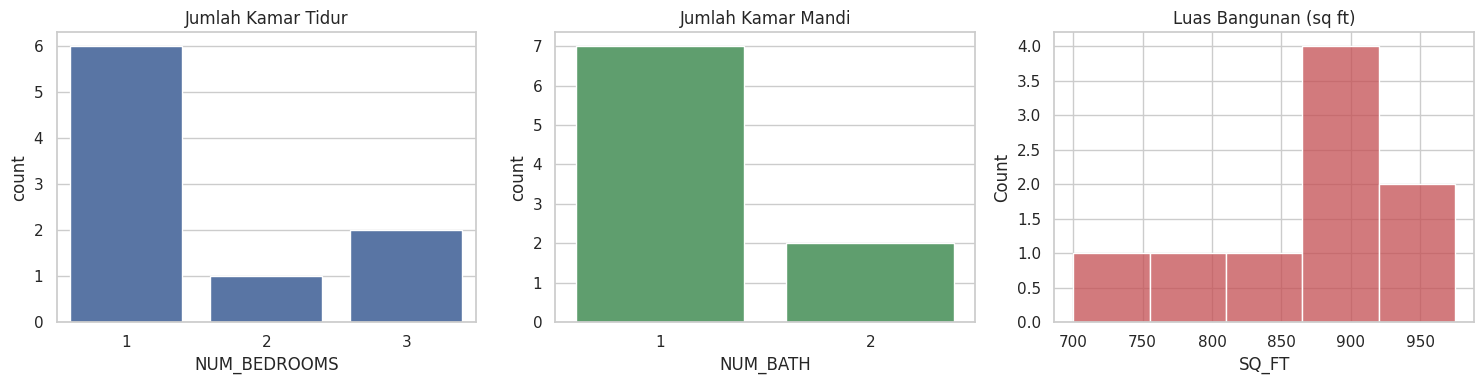

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="NUM_BEDROOMS", data=df_clean, ax=axes[0], color="#4C72B0")
axes[0].set_title("Jumlah Kamar Tidur")

sns.countplot(x="NUM_BATH", data=df_clean, ax=axes[1], color="#55A868")
axes[1].set_title("Jumlah Kamar Mandi")

sns.histplot(df_clean["SQ_FT"], bins=5, ax=axes[2], color="#C44E52")
axes[2].set_title("Luas Bangunan (sq ft)")

plt.tight_layout()
plt.show()

- **Kamar tidur:** mayoritas properti punya 1 kamar tidur; hanya satu yang punya 3.
- **Kamar mandi:** sebagian besar 1 kamar mandi.
- **Luas:** banyak properti berada di sekitar 900 sq ft.

### 5.3 Status Hunian (`OWN_OCCUPIED`)

OWN_OCCUPIED
Y    7
N    2
Name: count, dtype: int64


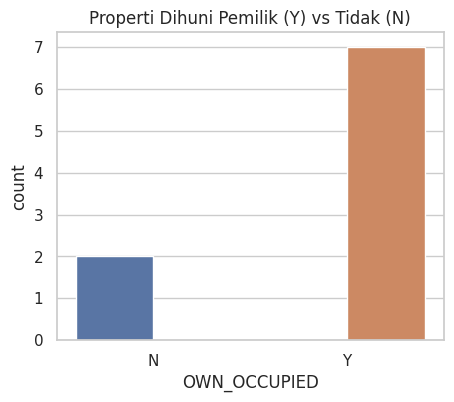

In [13]:
print(df_clean["OWN_OCCUPIED"].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(x="OWN_OCCUPIED", data=df_clean, palette=["#4C72B0", "#DD8452"], hue="OWN_OCCUPIED", legend=False)
plt.title("Properti Dihuni Pemilik (Y) vs Tidak (N)")
plt.show()

**7 dari 9 properti (sekitar 78%)** dihuni oleh pemiliknya sendiri.

### 5.4 Sebaran Properti per Jalan

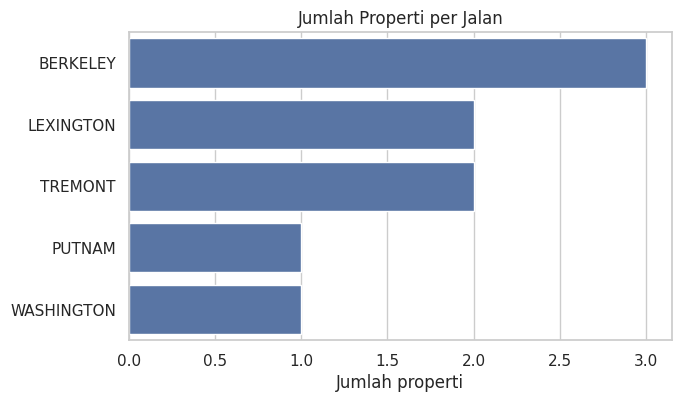

In [14]:
plt.figure(figsize=(7, 4))
order = df_clean["ST_NAME"].value_counts().index
sns.countplot(y="ST_NAME", data=df_clean, order=order, color="#4C72B0")
plt.title("Jumlah Properti per Jalan")
plt.xlabel("Jumlah properti")
plt.ylabel("")
plt.show()

`BERKELEY` punya properti terbanyak (3), diikuti `LEXINGTON` dan `TREMONT` (masing-masing 2). `PUTNAM` dan `WASHINGTON` masing-masing hanya 1.

### 5.5 Rata-rata Karakteristik per Jalan

In [15]:
per_jalan = (df_clean.groupby("ST_NAME")
             .agg(jumlah=("PID", "count"),
                  rata_kamar_tidur=("NUM_BEDROOMS", "mean"),
                  rata_kamar_mandi=("NUM_BATH", "mean"),
                  rata_luas=("SQ_FT", "mean"))
             .round(2)
             .sort_values("rata_luas", ascending=False))
per_jalan

,jumlah,rata_kamar_tidur,rata_kamar_mandi,rata_luas
ST_NAME,,,,
WASHINGTON,1,2.00,1.00,950.0
TREMONT,2,1.00,1.50,900.0
PUTNAM,1,3.00,1.00,900.0
LEXINGTON,2,1.00,1.00,875.0
BERKELEY,3,1.67,1.33,825.0


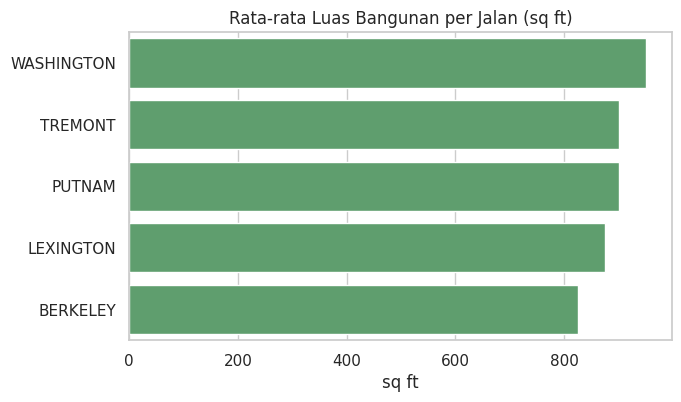

In [16]:
plt.figure(figsize=(7, 4))
sns.barplot(x="rata_luas", y=per_jalan.index, data=per_jalan, color="#55A868")
plt.title("Rata-rata Luas Bangunan per Jalan (sq ft)")
plt.xlabel("sq ft")
plt.ylabel("")
plt.show()

`WASHINGTON` punya rata-rata luas terbesar (950 sq ft) dan `BERKELEY` terkecil (825 sq ft). **Catatan:** `WASHINGTON` dan `PUTNAM` hanya berisi 1 properti, jadi angkanya bukan "rata-rata" yang bisa digeneralisasi.

### 5.6 Pemilik vs Bukan Pemilik

In [17]:
(df_clean.groupby("OWN_OCCUPIED", observed=True)[["NUM_BEDROOMS", "NUM_BATH", "SQ_FT"]]
         .mean().round(2))

,NUM_BEDROOMS,NUM_BATH,SQ_FT
OWN_OCCUPIED,,,
N,1.00,1.00,875.0
Y,1.71,1.29,875.0


Properti yang dihuni pemilik rata-rata punya lebih banyak kamar tidur (1,71) dan kamar mandi (1,29) dibanding yang tidak (1,00 dan 1,00), sedangkan luas rata-ratanya sama (875 sq ft). Namun grup `N` hanya berisi 2 properti, jadi ini baru gambaran awal.

### 5.7 Hubungan Antar Variabel Numerik (Korelasi)

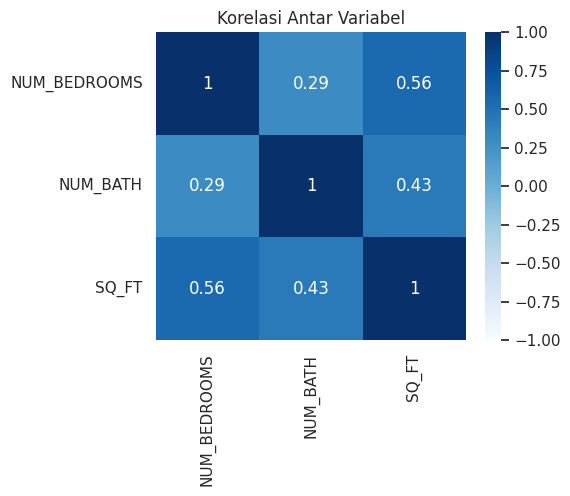

In [18]:
corr = df_clean[["NUM_BEDROOMS", "NUM_BATH", "SQ_FT"]].corr().round(2)

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=-1, vmax=1)
plt.title("Korelasi Antar Variabel")
plt.show()

Korelasi antara luas bangunan dan jumlah kamar tidur (0,56) serta kamar mandi (0,43) bernilai positif sedang: rumah yang lebih luas cenderung punya lebih banyak kamar. **Peringatan:** dengan hanya 9 data, korelasi sangat mudah berubah oleh satu baris saja, jadi jangan dijadikan bukti kuat.

## 6. Kesimpulan

1. **Kualitas data:** dataset berisi 9 properti dan 7 kolom. Tidak ada baris duplikat dan tidak ada *missing value*. Masalah yang ditemukan adalah (a) kolom ID salah nama (`lai`), (b) tipe data kurang tepat (jumlah kamar bertipe desimal, ID bertipe angka), dan (c) nama jalan tidak konsisten.
2. **Inkonsistensi:** `ST_NAME` awalnya punya 8 nilai unik (`berkeley`, `Berkeley`, `BERKELEY`, `LXT`, dll). Setelah diseragamkan menjadi **5 jalan unik**: BERKELEY, LEXINGTON, TREMONT, PUTNAM, WASHINGTON.
3. **Karakteristik properti:** properti umumnya berukuran kecil, rata-rata 875 sq ft (rentang 700 sampai 975), dengan median 1 kamar tidur dan 1 kamar mandi.
4. **Status hunian:** sekitar 78% (7 dari 9) properti dihuni pemilik.
5. **Per jalan:** `BERKELEY` paling banyak propertinya (3), dengan rata-rata luas terkecil (825 sq ft); `WASHINGTON` terluas (950 sq ft) tetapi hanya 1 properti.
6. **Hubungan variabel:** luas bangunan cenderung naik bersama jumlah kamar tidur dan kamar mandi, tetapi bukti ini lemah karena data sangat sedikit.

## 7. Saran

**Untuk kualitas data**
- Terapkan standar penulisan sejak input (misalnya selalu huruf kapital, tanpa singkatan) atau gunakan *dropdown* agar variasi seperti `LXT` dan `Berkeley` tidak muncul lagi.
- Beri nama kolom ID yang jelas (`PID`) dan simpan sebagai teks.
- Simpan hasil bersih (`property_clean.csv`) sebagai versi yang dipakai analisis, dan pertahankan file mentah apa adanya.

**Untuk analisis lanjutan**
- Tambah jumlah data. Dengan 9 baris, rata-rata dan korelasi belum bisa dipercaya untuk pengambilan keputusan.
- Tambahkan kolom yang lebih informatif seperti **harga**, tahun bangun, dan lokasi/koordinat. Dengan harga, kita bisa menganalisis harga per sq ft dan faktor pembentuk harga.
- Bila data sudah cukup besar, lanjutkan dengan uji statistik atau model regresi untuk menguji hubungan luas, jumlah kamar, dan harga.